# Solutions to notebook 2: Solving equations

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/solutions/02_equations.ipynb)

Worked solutions to the exercises at the end of [notebook 2](../notebooks/02_equations.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## Exercise 1

A mixer combines streams of 10 %, 30 % and 60 % acid to make 100 kg of 35 % acid, using twice
as much of the 30 % stream as the 10 % stream. Set up and solve the three balances.

In [2]:
m1, m2, m3 = sp.symbols("m_1 m_2 m_3", positive=True)     # kg of the 10 %, 30 % and 60 % streams

balances = [
    sp.Eq(m1 + m2 + m3, 100),                                                          # total mass
    sp.Eq(sp.Rational(10, 100) * m1 + sp.Rational(30, 100) * m2 + sp.Rational(60, 100) * m3,
          sp.Rational(35, 100) * 100),                                                 # acid
    sp.Eq(m2, 2 * m1),                                                                 # recipe
]
mix = sp.solve(balances, [m1, m2, m3])
mix

⎧    250      500      350⎫
⎨m₁: ───, m₂: ───, m₃: ───⎬
⎩    11       11       11 ⎭

In [3]:
# verify: substitute back into all three balances, and compare with the hand elimination.
# By hand: m2 = 2 m1 and m3 = 100 - 3 m1, so 0.7 m1 + 0.6 (100 - 3 m1) = 35 and m1 = 25/1.1.
assert all(eq.lhs.subs(mix) == eq.rhs.subs(mix) for eq in balances)
assert mix[m1] == sp.Rational(250, 11)
assert all(amount > 0 for amount in mix.values())
{stream: round(float(amount), 2) for stream, amount in mix.items()}        # kg

{m₁: 22.73, m₂: 45.45, m₃: 31.82}

**Answer.** $m_1 = 250/11 \approx 22.7$ kg of 10 % acid, $m_2 = 500/11 \approx 45.5$ kg of 30 % acid
and $m_3 = 350/11 \approx 31.8$ kg of 60 % acid. They add up to 100 kg and contain 35 kg of acid.

## Exercise 2

Repeat 2.3 for the Redlich–Kwong equation $P = \dfrac{RT}{V-b} - \dfrac{a}{\sqrt{T}\,V(V+b)}$.
`solve` may struggle: substitute $V = \xi b$, solve the first condition for $a$, substitute
into the second to get a cubic in $\xi$, and solve that numerically. Check that $Z_c = 1/3$.

In [4]:
V, T, R = sp.symbols("V T R", positive=True)
a, b, xi = sp.symbols("a b xi", positive=True)

P_rk = R * T / (V - b) - a / (sp.sqrt(T) * V * (V + b))

# the two critical-point conditions, written with V = xi*b
dP = sp.diff(P_rk, V).subs(V, xi * b)
d2P = sp.diff(P_rk, V, 2).subs(V, xi * b)

The first condition is linear in $a$. Solve it for $a$ and substitute into the second: $R$, $T$
and $b$ then cancel and a polynomial in $\xi$ alone is left.

In [5]:
a_from_dP = sp.solve(dP, a)[0]
xi_poly = sp.numer(sp.together(sp.simplify(d2P.subs(a, a_from_dP))))
xi_poly = sp.Poly(xi_poly, xi).monic().as_expr()      # divide by the leading coefficient
xi_poly

 3      2          
ξ  - 3⋅ξ  - 3⋅ξ - 1

In [6]:
xi_c = sp.nsolve(xi_poly, xi, 4)          # start near the van der Waals value of 3
xi_c

3.84732210186307

With $\xi_c$ known, the first condition gives $T_c$, and the equation of state gives $P_c$.

In [7]:
Vc = xi_c * b
Tc = sp.solve(sp.Eq(a, a_from_dP.subs(xi, xi_c)), T)[0]
Pc = sp.simplify(P_rk.subs({V: Vc, T: Tc}))
Vc, Tc, Pc

⎛                                       2/3                     3 ___  2/3⎞
⎜                    0.345039995853347⋅a     0.0298943859926415⋅╲╱ R ⋅a   ⎟
⎜3.84732210186307⋅b, ──────────────────────, ─────────────────────────────⎟
⎜                           2/3  2/3                      5/3             ⎟
⎝                          R   ⋅b                        b                ⎠

In [8]:
# verify 1: both derivatives vanish at the critical point (numbers for a, b, R chosen arbitrarily)
test = {a: 2.0, b: 0.5, R: 3.0}
point = {V: Vc.subs(test), T: Tc.subs(test)}
assert abs(sp.diff(P_rk, V).subs(test).subs(point)) < 1e-9
assert abs(sp.diff(P_rk, V, 2).subs(test).subs(point)) < 1e-9

# verify 2: textbook values for Redlich-Kwong: xi_c = 1/(2**(1/3) - 1), Z_c = 1/3,
# b = 0.08664 R Tc / Pc and a = 0.42748 R**2 Tc**2.5 / Pc
Zc = sp.simplify(Pc * Vc / (R * Tc))
Omega_b = sp.simplify(b * Pc / (R * Tc))
Omega_a = sp.simplify(a * Pc / (R**2 * Tc ** sp.Rational(5, 2)))
assert abs(xi_c - 1 / (2 ** (1 / 3) - 1)) < 1e-12
assert abs(Zc - sp.Rational(1, 3)) < 1e-12
assert abs(Omega_b - 0.08664) < 1e-5 and abs(Omega_a - 0.42748) < 1e-5
Zc, Omega_b, Omega_a

(0.333333333333332, 0.0866403499649575, 0.427480233540341)

**Answer.** $\xi_c$ is the real root of $\xi^3 - 3\xi^2 - 3\xi - 1 = 0$, which is
$\xi_c = 1/(2^{1/3} - 1) \approx 3.847$. The critical point is

$$V_c \approx 3.847\,b,\qquad T_c \approx 0.3450\left(\frac{a}{bR}\right)^{2/3},\qquad
P_c \approx 0.02989\,\frac{a^{2/3}R^{1/3}}{b^{5/3}} .$$

The critical compressibility factor is $Z_c = 1/3$ for every Redlich–Kwong fluid, compared with
$3/8$ for van der Waals. Inverting the results gives the familiar constants
$b = 0.08664\,RT_c/P_c$ and $a = 0.42748\,R^2T_c^{2.5}/P_c$.

## Exercise 3

Raise the temperature in 2.4 to 320 K (above $T_c$). How many real roots remain?
Use `[r for r in roots if r.is_real]`.

In [9]:
P = sp.symbols("P", positive=True)
P_vdw = R * T / (V - b) - a / V**2
cubic = sp.numer(sp.together(P - P_vdw))       # numerator of P - P_vdw = 0, a polynomial in V

co2 = {a: 0.3640, b: 4.267e-5, R: 8.314, T: 320, P: 50e5}
roots = sp.Poly(cubic.subs(co2), V).nroots()
roots       # m^3/mol

[0.00041857128936452, 7.80973553177398e-5 - 3.6361816095512e-5⋅ⅈ, 7.8097355317 ↪

↪ 7398e-5 + 3.6361816095512e-5⋅ⅈ]

In [10]:
real_roots = [r for r in roots if r.is_real]
V_gas = float(real_roots[0])

# verify: the root reproduces 50 bar, the temperature is above the van der Waals critical
# temperature 8a/(27Rb), and the volume is a little below the ideal-gas value RT/P
Tc_co2 = 8 * co2[a] / (27 * co2[R] * co2[b])
V_ideal = co2[R] * co2[T] / co2[P]
assert len(real_roots) == 1
assert abs(float(P_vdw.subs(co2).subs(V, V_gas)) / co2[P] - 1) < 1e-9
assert co2[T] > Tc_co2 and 0.5 * V_ideal < V_gas < V_ideal
print(f"T_c = {Tc_co2:.0f} K,  V = {V_gas * 1e6:.0f} cm³/mol,  ideal gas {V_ideal * 1e6:.0f} cm³/mol")

T_c = 304 K,  V = 419 cm³/mol,  ideal gas 532 cm³/mol


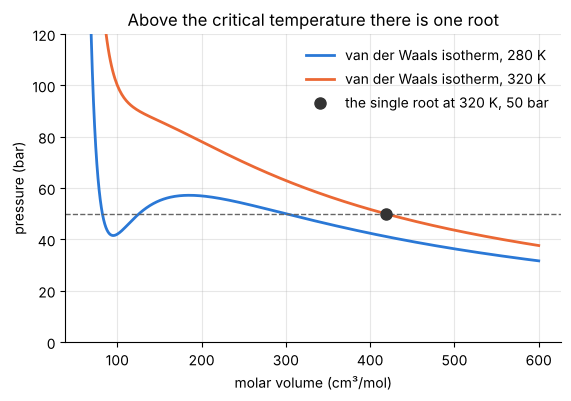

In [11]:
Vg = np.linspace(6.5e-5, 6e-4, 400)
fig, ax = plt.subplots()
for temperature in (280, 320):
    P_fun = sp.lambdify(V, P_vdw.subs({a: co2[a], b: co2[b], R: co2[R], T: temperature}), "numpy")
    ax.plot(Vg * 1e6, P_fun(Vg) / 1e5, label=f"van der Waals isotherm, {temperature} K")
ax.axhline(50, color="0.4", lw=1, ls="--")
ax.plot(V_gas * 1e6, 50, "o", color="0.2", ms=8, label="the single root at 320 K, 50 bar")
ax.set(xlabel="molar volume (cm³/mol)", ylabel="pressure (bar)", ylim=(0, 120),
       title="Above the critical temperature there is one root")
ax.legend(frameon=False);

**Answer.** One real root remains, $V \approx 4.2\times10^{-4}$ m³/mol (about 419 cm³/mol,
against 532 cm³/mol for an ideal gas). The other two roots are a complex-conjugate pair with no
physical meaning. Above the critical
temperature (304 K for these constants) the isotherm falls monotonically, so a horizontal line
at 50 bar crosses it once: there is a single fluid phase and no liquid–vapour distinction.

## Exercise 4

For $Re = 10^6$, how rough must a pipe be before $f$ exceeds 0.02? Write the original
Colebrook equation with $f = 0.02$ and solve for $\varepsilon/D$. The unknown now appears
only once, so `sp.solve` finds a closed form. (Answer: about $1.0\times10^{-3}$.)

In [12]:
f, Re, eps_r = sp.symbols("f Re epsilon_r", positive=True)

colebrook_f = sp.Eq(1 / sp.sqrt(f),
                    -2 * sp.log(eps_r / sp.Rational(37, 10) + sp.Rational(251, 100) / (Re * sp.sqrt(f)), 10))

eps_expr = sp.solve(colebrook_f, eps_r)[0]       # solving for eps_r is safe; solving for f is not
eps_expr

                    -1  
                    ────
                    2⋅√f
     9287      37⋅10    
- ────────── + ─────────
  1000⋅Re⋅√f      10    

In [13]:
eps_num = float(eps_expr.subs({f: sp.Rational(2, 100), Re: 10**6}))
eps_num

0.0010124527694471282

In [14]:
# verify 1: the closed form derived by hand, eps/D = 3.7 (10**(-1/(2 sqrt(f))) - 2.51/(Re sqrt(f)))
eps_hand = 3.7 * (10 ** (-1 / (2 * np.sqrt(0.02))) - 2.51 / (1e6 * np.sqrt(0.02)))
assert abs(eps_num / eps_hand - 1) < 1e-9

# verify 2: solve Colebrook numerically for the friction factor with this roughness (as in 2.5)
X = sp.symbols("X", positive=True)
colebrook_X = sp.Eq(X, -2 * sp.log(eps_r / sp.Rational(37, 10) + sp.Rational(251, 100) * X / Re, 10))
X_num = sp.nsolve(colebrook_X.subs({Re: 1e6, eps_r: eps_num}), X, 7)
assert abs(float(1 / X_num**2) - 0.02) < 1e-9
print(f"eps/D = {eps_num:.3e} gives f = {float(1 / X_num**2):.5f}")

eps/D = 1.012e-03 gives f = 0.02000


**Answer.** $\dfrac{\varepsilon}{D} = 3.7\left(10^{-1/(2\sqrt f)} - \dfrac{2.51}{Re\sqrt f}\right)
\approx 1.01\times10^{-3}$ for $f = 0.02$ and $Re = 10^6$, in agreement with the stated answer.
The friction factor rises with roughness, so $f$ exceeds 0.02 for any pipe rougher than this:
about 0.1 mm of roughness on a 100 mm pipe.